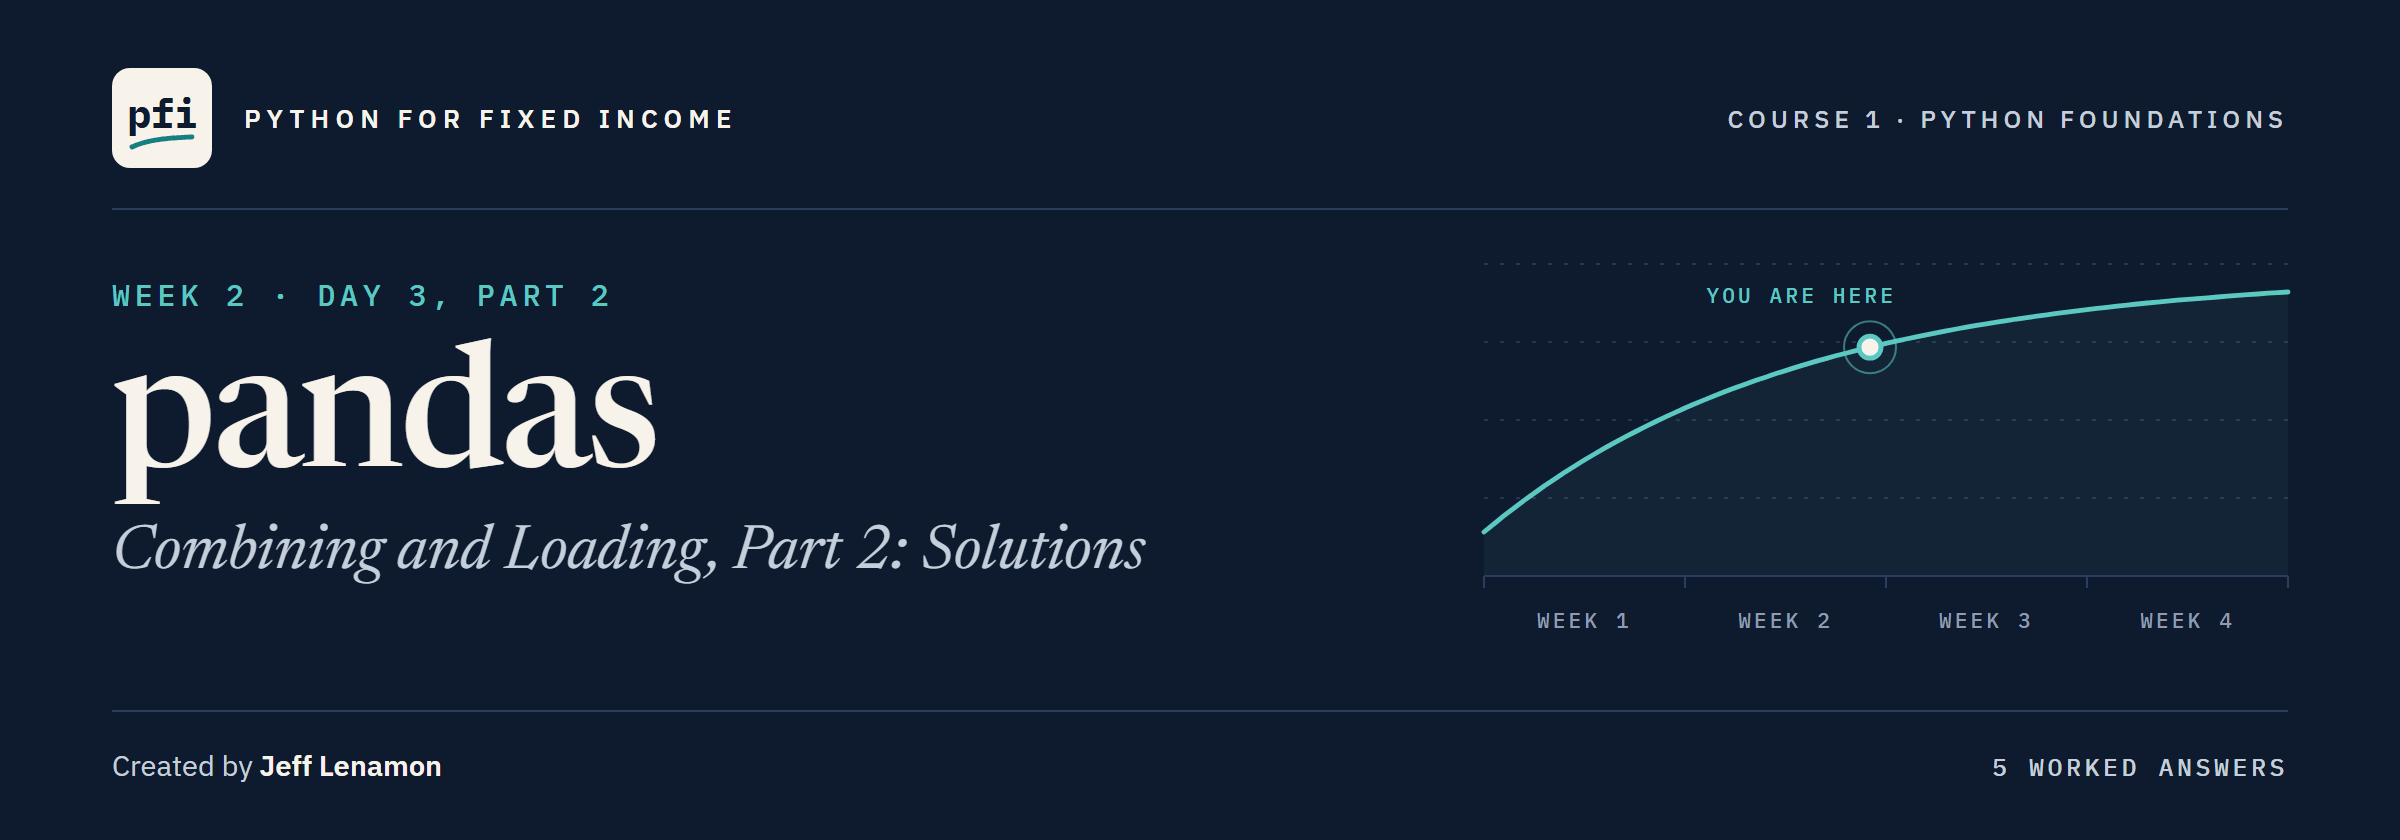

# pandas: Combining and Loading, Part 2: Solutions

Week 2, Day 3, Part 2. Worked answers to the exercises. Try each one yourself first.

> This course is educational content created in a personal capacity. Nothing here is investment advice or a recommendation to buy or sell any security. All portfolio data is synthetic.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course01_python_foundations/week2/day3_part2/08_part2_pandas_combining_and_loading_solutions.ipynb)

## Exercises

These are the worked answers to the exercises in the teaching notebook.
They use the holdings file and the rating scale; the issuers are invented.

Each answer is followed by the check cell from the teaching notebook.
Run the next two cells first: the first defines `check`, which marks your answers; the second loads fresh copies of the two files.

In [1]:
# check() compares your answer with the expected one and prints the result
def check(label, answer, expected):
    if answer is ...:
        print(label + ': not attempted yet')
        return
    if answer is None:
        print(label + ': not yet. Nothing came back: does your function end with return?')
        return
    # isinstance(x, list) is True when x is a list, so a list answer is compared value by value
    if isinstance(expected, list):
        correct = list(answer) == expected  # the same values in the same order
    # getattr(answer, 'ndim', 0) reads answer's ndim, its number of dimensions, as in NumPy
    # Part 1, and gives 0 when answer has none: a single number or a piece of text
    elif getattr(answer, 'ndim', 0) > 0:
        correct = False  # a column or a table where one value is expected
    elif isinstance(expected, float):
        # abs() drops the sign, so this is the size of the gap between the two decimals
        correct = abs(answer - expected) < 0.000001  # decimals: within a tiny tolerance
    else:
        correct = answer == expected
    print(label + ': correct' if correct else label + ': not yet. You have ' + str(answer))

In [2]:
import os

import pandas as pd

# fresh copies of two files. In Colab they are read from GitHub.
if os.path.exists('../../../data/holdings.csv'):
    data_folder = '../../../data/'
else:
    data_folder = 'https://raw.githubusercontent.com/lenamonj/python-fixed-income/main/data/'

holdings = pd.read_csv(data_folder + 'holdings.csv')
ratings = pd.read_csv(data_folder + 'ratings.csv')
print(holdings.shape, ratings.shape)

(200, 19) (18, 4)


### Exercise 1

Q. Keep the High Yield bonds of the holdings. What is their market-value-weighted average OAS, and their market-value-weighted average duration? Round both to two decimal places and store them in **ex1_hy_oas** and **ex1_hy_duration**.

In [3]:
# the grade comes from the rating scale
book = pd.merge(holdings, ratings, on='rating')
hy = book[book['grade'] == 'High Yield']

# sum of value times weight, divided by the sum of the weights
hy_value = hy['market_value'].sum()
ex1_hy_oas = round((hy['oas'] * hy['market_value']).sum() / hy_value, 2)
ex1_hy_duration = round((hy['duration'] * hy['market_value']).sum() / hy_value, 2)

print('High yield bonds:', hy.shape[0])
print('Weighted average OAS:', ex1_hy_oas)
print('Weighted average duration:', ex1_hy_duration)

High yield bonds: 72
Weighted average OAS: 334.73
Weighted average duration: 5.43


The 72 high yield bonds have a weighted average OAS of 334.73 basis points and a weighted average duration of 5.43 years.
The simple averages are 339.38 and 5.74, so weighting by market value lowers both.

In [4]:
check('Exercise 1 OAS', ex1_hy_oas, 334.73)
check('Exercise 1 duration', ex1_hy_duration, 5.43)

Exercise 1 OAS: correct
Exercise 1 duration: correct


### Exercise 2

Q. Convert the maturity column of the holdings to dates. How many bonds mature in the years 2040 to 2049? What is the CUSIP of the bond with the latest maturity date? Store the answers in **ex2_count** and **ex2_last_cusip**.

In [5]:
# text to dates, then the year of each date
holdings['maturity'] = pd.to_datetime(holdings['maturity'])
maturity_year = holdings['maturity'].dt.year

# both conditions must hold, so combine them with &
in_2040s = (maturity_year >= 2040) & (maturity_year <= 2049)
ex2_count = in_2040s.sum()
print('Bonds maturing in 2040 to 2049:', ex2_count)

# sort with the latest date first, and take the CUSIP of the first row
latest_first = holdings.sort_values('maturity', ascending=False)
ex2_last_cusip = latest_first['cusip'].iloc[0]
print('Latest maturity:', ex2_last_cusip)

latest_first[['cusip', 'ticker', 'coupon', 'maturity']].head(3)

Bonds maturing in 2040 to 2049: 17
Latest maturity: 99111HAB6


,cusip,ticker,coupon,maturity
189,99111HAB6,XANE,5.75,2056-08-23
153,99124UAE6,THAL,8.00,2056-03-15
184,99074WAD4,WYXA,6.75,2056-02-23


17 bonds mature in the 2040s.
The latest maturity is the XANE 5.75% of 2056-08-23, CUSIP 99111HAB6.

In [6]:
check('Exercise 2 count', ex2_count, 17)
check('Exercise 2 last CUSIP', ex2_last_cusip, '99111HAB6')

Exercise 2 count: correct
Exercise 2 last CUSIP: correct


### Exercise 3

Exercise 1 worked out two weighted averages with the same two steps.
A function holds the steps once, and runs them on any column, any table, and next month's file.

Q. Write a function `weighted_average(table, value_column, weight_column)` that takes a table and the names of two of its columns, and returns the average of the first column weighted by the second, rounded to two decimal places. The first line and the docstring are given; replace `return ...` with your code, ending in a `return` line. Then call it to find the market-value-weighted average coupon of the whole holdings file, and store the answer in **ex3_coupon**.

In [7]:
def weighted_average(table, value_column, weight_column):
    """
    Take a table, the name of the column to average, and the name of the column of weights,
    and return the weighted average, rounded to two decimal places.
    """
    # sum of value times weight, divided by the sum of the weights
    total = (table[value_column] * table[weight_column]).sum()
    return round(total / table[weight_column].sum(), 2)


# the same function, called for two columns of the holdings
ex3_coupon = weighted_average(holdings, 'coupon', 'market_value')
print(f'Weighted average coupon: {ex3_coupon:.2f} percent')
print(f"Weighted average OAS: {weighted_average(holdings, 'oas', 'market_value'):.2f} basis points")

Weighted average coupon: 5.95 percent
Weighted average OAS: 180.46 basis points


5.95 percent for the coupon, and 180.46 basis points for the OAS, the figure from section 8.7 of the lesson.
The column names arrive as text, so `table[value_column]` picks whichever column was asked for: one function covers OAS, duration, coupon, and any weight.
On the high yield rows alone, `weighted_average(hy, 'oas', 'market_value')` returns the 334.73 of Exercise 1.

In [8]:
# the first check calls your function on the holdings
check('Exercise 3 OAS', weighted_average(holdings, 'oas', 'market_value'), 180.46)
check('Exercise 3 coupon', ex3_coupon, 5.95)

Exercise 3 OAS: correct
Exercise 3 coupon: correct


### Exercise 4

Q. Merge the holdings with the rating scale. Build one table with a row for each sector and two columns, `bonds` (the number of bonds) and `avg_duration` (the average duration), using `groupby` and `agg`. Build a second table with the sector's total market value in a column called `total_value`. Join the two tables on their index and store the result in **ex4_table**. Store the total value of the Technology sector in **ex4_technology_value**. Then convert the day-first dates `31/12/2030` and `01/02/2031` and write them as text in the layout `31 Dec 2030`, and store the two strings as a list in **ex4_labels**.

In [9]:
book = pd.merge(holdings, ratings, on='rating')

# one row per sector, two named statistics
counts = book.groupby('sector').agg(bonds=('cusip', 'count'), avg_duration=('duration', 'mean'))

# one row per sector, the total market value in a column of its own
values = book.groupby('sector').agg(total_value=('market_value', 'sum'))

# join matches on the index, which is the sector in both tables
ex4_table = counts.join(values)
ex4_technology_value = ex4_table.loc['Technology', 'total_value']
print(ex4_table.shape)
print('Technology total value:', ex4_technology_value)

# dayfirst=True reads 01/02/2031 as the 1st of February, and strftime writes the layout
dates = pd.to_datetime(pd.Series(['31/12/2030', '01/02/2031']), dayfirst=True)
ex4_labels = dates.dt.strftime('%d %b %Y').tolist()
print(ex4_labels)

(10, 3)
Technology total value: 30311760.0
['31 Dec 2030', '01 Feb 2031']


The joined table has 10 rows and 3 columns.
Technology holds 30,311,760 of market value across 12 bonds.
The two labels are `31 Dec 2030` and `01 Feb 2031`.
Without `dayfirst=True` the second date would have been read as the 2nd of January.

In [10]:
check('Exercise 4 table shape', ... if ex4_table is ... else list(ex4_table.shape), [10, 3])
check('Exercise 4 Technology value', ex4_technology_value, 30311760.0)
check('Exercise 4 labels', ex4_labels, ['31 Dec 2030', '01 Feb 2031'])

Exercise 4 table shape: correct
Exercise 4 Technology value: correct
Exercise 4 labels: correct


### Exercise 5: AI check

You ask an AI assistant for the market-value-weighted average OAS of the desk's High Yield bonds.
It gives you the code below.
It was written for this course in the style of an AI answer, and it has one bug.

Q. Read the code before you run it. What number do you expect? You worked it out yourself in Exercise 1. Then run the code. Does it agree with you?

The answer from Exercise 1 is 334.73 basis points.
The original code printed 339.38, with no error.
The bug was the last step: the code merged and filtered correctly, then took `hy['oas'].mean()`, the simple average, where every bond counts the same whatever its size.
The comment said weighted, and the code never used `market_value`.
339.38 is a believable high yield spread, under 5 basis points from the right answer.
Two checks catch it: a figure worked out independently, and reading the code for the column a weighted average must use.

In [11]:
# bring in the grade and keep the high yield bonds
book = pd.merge(holdings, ratings, on='rating')
hy = book[book['grade'] == 'High Yield']

# weighted average: sum of OAS times market value, divided by the sum of market value
ex5_hy_oas = round((hy['oas'] * hy['market_value']).sum() / hy['market_value'].sum(), 2)

print(f'Weighted average OAS of the High Yield bonds: {ex5_hy_oas}')

Weighted average OAS of the High Yield bonds: 334.73


In [12]:
check('Exercise 5 OAS', ex5_hy_oas, 334.73)

Exercise 5 OAS: correct


[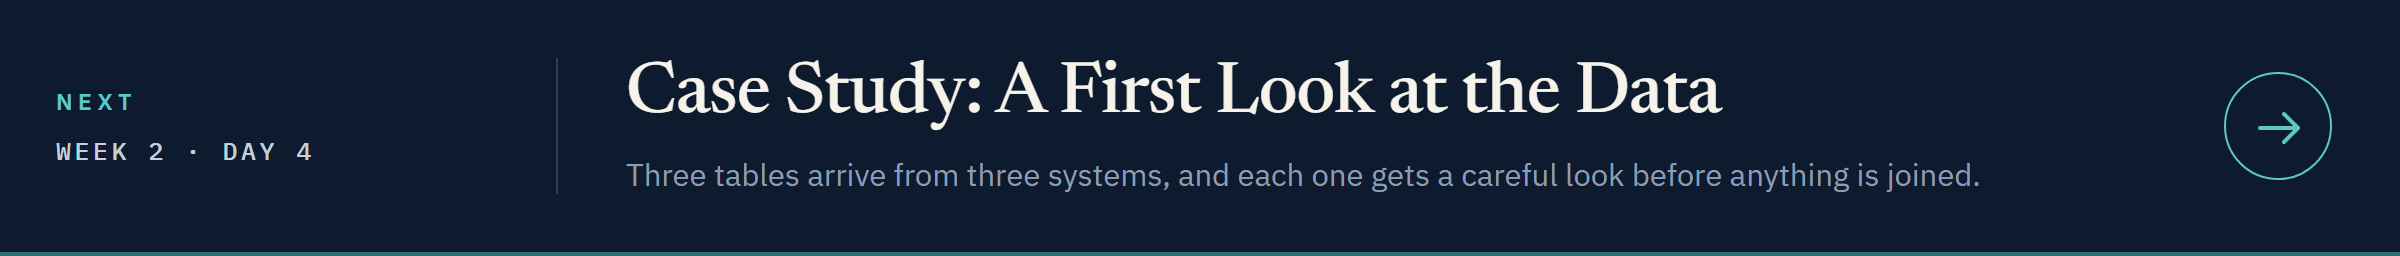](../day4/09_case_study_first_look_at_the_data.ipynb)

[Open Day 4 in Colab](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course01_python_foundations/week2/day4/09_case_study_first_look_at_the_data.ipynb)